# 03 · CNN: experimentos

Pré-requisito: `python -m scripts.run_experiments --plan configs/experiments_rapido.yaml --seeds 0` (protocolo rápido) ou o protocolo completo com `configs/experiments.yaml` e 3 seeds.

In [1]:
import sys
sys.path.append("..")
import os
os.chdir("..")  # roda a partir da raiz do projeto, como os scripts

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import Markdown

## 1. Tabela de resultados (validação)

In [2]:
Markdown(open("results/cnn/experimentos.md", encoding="utf-8").read())

| Experimento | Acurácia de validação (%) | Desvio | s/época |
| --- | --- | --- | --- |
| E3_dropout_025 | 91.96 | n/d (1 seed) | 35.7 |
| E5_cosine | 91.77 | n/d (1 seed) | 35.1 |
| E2_batchnorm | 91.65 | n/d (1 seed) | 47.4 |
| E0_base | 91.50 | n/d (1 seed) | 47.3 |
| E3_dropout_050 | 91.49 | n/d (1 seed) | 33.5 |
| E4_augmentation | 90.77 | n/d (1 seed) | 34.9 |
| E1_lr_1e-2 | 90.61 | n/d (1 seed) | 39.4 |
| E1_lr_1e-4 | 88.24 | n/d (1 seed) | 41.0 |


## 2. Curvas de validação de todos os experimentos

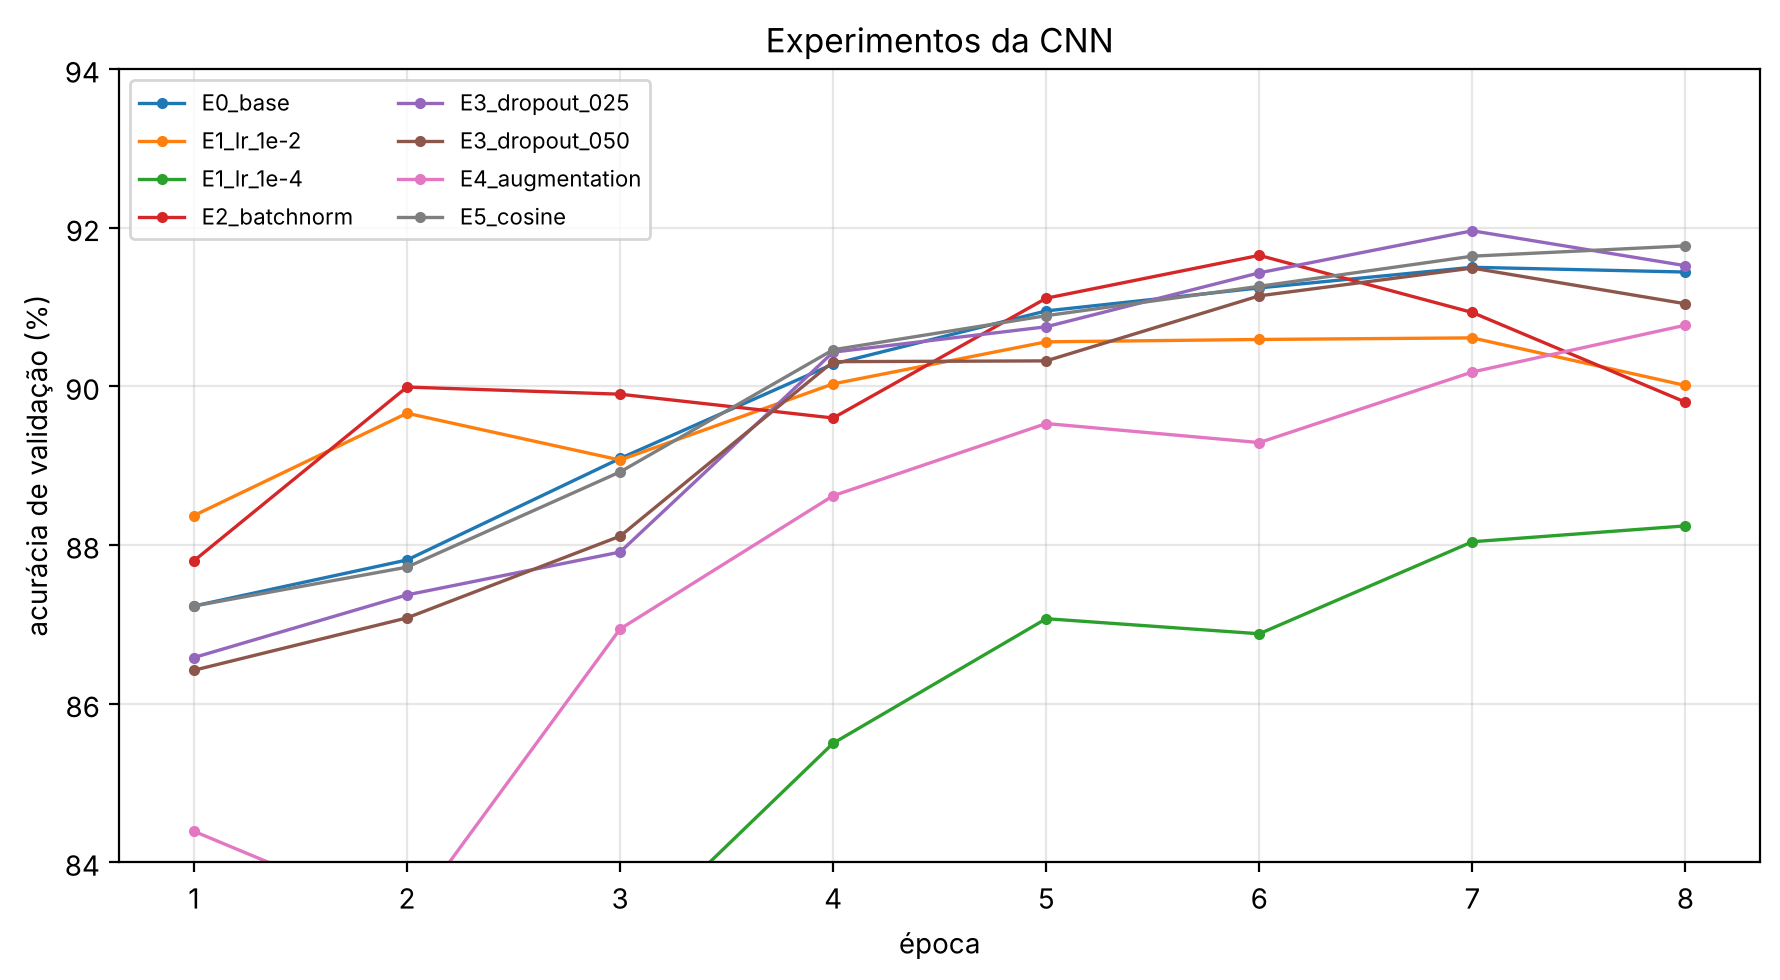

In [3]:
import glob
fig, ax = plt.subplots(figsize=(9, 5))
for path in sorted(glob.glob("results/cnn/E*_seed0/metrics.csv")):
    d = pd.read_csv(path)
    name = path.split("/")[-2].replace("_seed0", "")
    ax.plot(d.epoch, 100 * d.val_acc, marker=".", label=name, lw=2.5 if name.startswith("E6") else 1.2)
ax.set(xlabel="época", ylabel="acurácia de validação (%)", title="Experimentos da CNN")
ax.set_ylim(84, 94); ax.legend(fontsize=8, ncol=2); ax.grid(alpha=.3); plt.tight_layout()

## 3. Overfitting por experimento

In [4]:
rows = []
for path in sorted(glob.glob("results/cnn/E*_seed0/metrics.csv")):
    d = pd.read_csv(path)
    b = d.loc[d.val_acc.idxmax()]
    rows.append({"experimento": path.split("/")[-2].replace("_seed0", ""),
                 "melhor val (%)": round(100 * b.val_acc, 2),
                 "treino na mesma época (%)": round(100 * b.train_acc, 2),
                 "gap (p.p.)": round(100 * (b.train_acc - b.val_acc), 2),
                 "época": int(b.epoch)})
pd.DataFrame(rows).sort_values("melhor val (%)", ascending=False).reset_index(drop=True)

,experimento,melhor val (%),treino na mesma época (%),gap (p.p.),época
0,E3_dropout_025,91.96,92.15,0.19,7
1,E5_cosine,91.77,93.59,1.82,8
2,E2_batchnorm,91.65,94.03,2.38,6
3,E0_base,91.50,93.17,1.67,7
4,E3_dropout_050,91.49,90.88,-0.61,7
5,E4_augmentation,90.77,89.68,-1.09,8
6,E1_lr_1e-2,90.61,93.06,2.45,7
7,E1_lr_1e-4,88.24,88.15,-0.09,8


Como ler: experimentos de regularização (dropout, augmentation) devem **reduzir o gap** entre treino e validação. Se reduzem o gap mas não aumentam a validação em 8 épocas, é sinal de que precisam de mais épocas para render.